# 1. Introduction
# ICU Survival Cox and Predictive Models

**Approach**  
Part 2 moves from description (KM curve) to explanation with the Cox proportional hazards model (CPH), and then to individual absolute risk at fixed horizons. Tree-based classifiers follow in notebook 03

**Learning goals**  
- Fit and interpret a Cox proportional hazards model in lifelines  
- Check the proportional hazards assumption and address violations  
- Translate hazard ratios into individualized survival curves  
- Turn cause-specific Cox models into absolute risks with competing risks (death vs discharge) at 7, 30, and 60 days  
- Check discrimination (C-index, time-dependent AUC) and calibration (Brier score, calibration plots)  
- Avoid data leakage and ensure reproducible 70 percent, 20 percent, 10 percent splits

**Methods and data**  
- Data  
  • [PhysioNet Challenge 2012 dataset](https://physionet.org/content/challenge-2012/1.0.0/), Set A aggregate file  
  • We standardize to `duration_days` and `event_death` to keep Part 1 and Part 2 consistent  

- Software  
  • lifelines for Cox and diagnostics  
  • scikit-learn for preprocessing, classifiers, and calibration  
  • scikit-survival for time-dependent AUC and integrated Brier score  

**Key references**  
- PhysioNet Challenge 2012 overview and dataset  
  • https://physionet.org/challenge/2012/  
- lifelines CoxPHFitter and assumption checks  
  • https://lifelines.readthedocs.io/en/latest/fitters/regression/CoxPHFitter.html  
- scikit-learn documentation  
  • Pipeline and ColumnTransformer: https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html  
  • CalibrationDisplay: https://scikit-learn.org/stable/modules/generated/sklearn.calibration.CalibrationDisplay.html  
  • Brier score: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.brier_score_loss.html  
- scikit-survival time-dependent metrics  
  • cumulative_dynamic_auc: https://scikit-survival.readthedocs.io/en/stable/api/generated/sksurv.metrics.cumulative_dynamic_auc.html


# 2. Setup

In [1]:
# Setup and reproducibility

import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import os
import sys
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Survival modeling
import lifelines
from lifelines import KaplanMeierFitter, CoxPHFitter, AalenJohansenFitter

# Scikit-learn core utilities
import sklearn
from sklearn import set_config
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    RocCurveDisplay,
    PrecisionRecallDisplay
)
from sklearn.calibration import CalibrationDisplay
from sklearn.model_selection import train_test_split, StratifiedKFold
from sksurv.nonparametric import cumulative_incidence_competing_risks
from sksurv.util import Surv
from sksurv.metrics import cumulative_dynamic_auc, brier_score
from sklearn.isotonic import IsotonicRegression

# Persistence
import joblib

# Local helpers supplied with Part 1
import utils

# Optional scikit-survival for time-dependent metrics
SKSURV_AVAILABLE = False
try:
    from sksurv.metrics import cumulative_dynamic_auc, integrated_brier_score
    from sksurv.util import Surv
    SKSURV_AVAILABLE = True
except ImportError as e:
    print("scikit-survival not available. Time-dependent metrics will be skipped.")
    print(f"Import error: {e}")

# Global configuration
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Matplotlib defaults for simple, readable figures
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["font.size"] = 11

# Show library versions for reproducibility
def _get_ver(mod):
    return getattr(mod, "__version__", "n/a")

print("Versions")
print(f"python              : {sys.version.split()[0]}")
print(f"numpy               : {_get_ver(np)}")
print(f"pandas              : {_get_ver(pd)}")
print(f"lifelines           : {_get_ver(lifelines)}")
print(f"scikit-learn        : {_get_ver(sklearn)}")
print(f"scikit-survival     : {'available' if SKSURV_AVAILABLE else 'not available'}")

# Ensure consistent display
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 120)

Versions
python              : 3.11.6
numpy               : 2.3.5
pandas              : 2.3.3
lifelines           : 0.30.3
scikit-learn        : 1.9.1
scikit-survival     : available


# 3. Load data and define variables

### Predictor selection and leakage control

- We will use only variables that are known or measured at or near ICU admission (avoids hindsight bias and leakage)
- We will exclude any variable that is a direct consequence of the outcome or occurs late in the stay (post-outcome signals inflate accuracy)
- We will explicitly drop `Length_of_stay` and any outcome derived fields to avoid label leakage (leak outcome information into predictors)
- We will keep preprocessing simple and transparent to support clinical interpretability

In [2]:
# --- 1. Load Data ---
PATH = "PhysionetChallenge2012-set-a.csv.gz"

# Simple check to ensure the data file exists before trying to load it
if not os.path.exists(PATH):
    raise FileNotFoundError(
        f"Error: The data file was not found at '{PATH}'. "
        "Please ensure the dataset is in the correct directory."
    )

ICU = pd.read_csv(PATH, compression="gzip")

# --- 2. Define the survival outcome (same as notebook 01) ---
# Duration = Length_of_stay: days from ICU admission to hospital discharge or in-hospital death
# Event    = In-hospital_death: 1 = died in hospital, 0 = discharged alive (competing event)
# Do NOT use 'Survival' as duration: it is days to death within 2 years and is -1 when no death
# was recorded. Using it would keep only patients who eventually died and would censor
# discharged patients at their (post-discharge) death date
duration_col = "Length_of_stay"
event_col = "In-hospital_death"

if duration_col not in ICU.columns or event_col not in ICU.columns:
    raise ValueError(f"Could not find required columns: '{duration_col}' or '{event_col}'")

# Create standardized fields for consistency across notebooks
ICU["duration_days"] = ICU[duration_col].astype(float).clip(lower=0)  # one record has LOS = -1
ICU["event_death"] = ICU[event_col].astype(int)

# --- 3. Validate and Clean Data ---
ICU.dropna(subset=["duration_days", "event_death"], inplace=True)
ICU = ICU[ICU["event_death"].isin([0, 1])].copy()  # Ensure event is 0 or 1

# --- 4. Final Data Summary ---
print(f"Data successfully loaded and cleaned. Final dataset has {len(ICU)} rows.")

# Display a preview of key columns as a formatted table
print("\nPreview of standardized data:")
preview_cols = ["duration_days", "event_death", "Age", "Gender", "SAPS-I", "SOFA"]
preview_cols = [c for c in preview_cols if c in ICU.columns]
display(ICU[preview_cols].head())

# Display descriptive statistics for the survival variables
print("\nDescriptive statistics for survival variables:")
display(ICU[["duration_days", "event_death"]].describe())

# Display the final counts of events vs. censored cases
print("\nEvent and censoring counts:")
display(ICU["event_death"].value_counts().rename({0: "Censored (Discharged alive)", 1: "Event (In-hospital death)"}).to_frame("Count"))

Data successfully loaded and cleaned. Final dataset has 4000 rows.

Preview of standardized data:


,duration_days,event_death,Age,Gender,SAPS-I,SOFA
0,5.0,0,54.0,0.0,6,1
1,8.0,0,76.0,1.0,16,8
2,19.0,0,44.0,0.0,21,11
3,9.0,0,68.0,1.0,7,1
4,4.0,0,88.0,0.0,17,2



Descriptive statistics for survival variables:


,duration_days,event_death
count,4000.000000,4000.000000
mean,13.456750,0.138500
std,12.229269,0.345467
min,0.000000,0.000000
25%,6.000000,0.000000
50%,10.000000,0.000000
75%,17.000000,0.000000
max,154.000000,1.000000



Event and censoring counts:


,Count
event_death,
Censored (Discharged alive),3446
Event (In-hospital death),554



**Check before modelling:** 4,000 stays, 554 in-hospital deaths (13.9%), the rest discharged alive. Same cohort and outcome as notebook 01

> Watch out: an earlier version of this notebook used `Survival` as the duration. That silently dropped 2,529 patients (all with no recorded death) and kept a cohort in which everyone eventually died. Always check that the cohort size and event rate match what you expect before fitting anything


## 3.1. Predictor curation and leakage control

Restricting predictors to admission-time variables to support real decisions and valid inference. We remove outcome proxies and identifiers to prevent label leakage and inflated accuracy e.g.

- Exclude duration, event, `Length_of_stay`, and any ID fields
- Prefer a small, clinically sensible shortlist of common variables
- Drop any remaining variables with more than 30% missingness
- Build a clean modeling frame with predictors plus `duration_days` and `event_death`

**Clinical considerations**
- Keeping features interpretable supports decisions making
- Removing downstream variables like `Length_of_stay` avoids inflated performance
- A simpler, curated feature set often leads to a more robust and generalizable model (than using hundreds of raw variables)

In [3]:
# --- 1. Define Columns to Exclude ---

# Define columns related to the outcome or that "leak" future information
leakage_cols = [
    "duration_days", "event_death", "Survival", "In-hospital_death", "Length_of_stay"
]

# Find columns that look like identifiers
id_cols = [col for col in ICU.columns if "id" in col.lower() or "record" in col.lower()]

# Combine all columns to be removed from the feature set
cols_to_exclude = leakage_cols + id_cols

# --- 2. Select Candidate Features ---

# Start with all columns and remove the ones we've identified for exclusion
candidate_features = [col for col in ICU.columns if col not in cols_to_exclude]

# For this course, we'll focus on a curated list of common, clinically relevant predictors
# This improves model interpretability and stability.
curated_shortlist = [
    "Age", "Gender", "SAPS-I", "SOFA", "Height", "Weight",
    "CCU", "CSRU", "SICU"
]

# Use only the curated features that are actually present in our dataset
X_candidates = [col for col in curated_shortlist if col in candidate_features]


# --- 3. Filter by Missingness ---

# Calculate the percentage of missing values for our candidate features
missing_rate = ICU[X_candidates].isna().mean().sort_values(ascending=False)

# Identify features where more than 30% of the data is missing
too_missing = missing_rate[missing_rate > 0.30].index.tolist()

# The final list of features is our candidate list, excluding the ones with too much missing data
X_features = [col for col in X_candidates if col not in too_missing]

# --- 4. Report and Create Final DataFrame ---

print("--- Predictor Selection Report ---")
print(f"Excluded for leakage/ID : {sorted(list(set(cols_to_exclude) & set(ICU.columns)))}")
print(f"Removed for >30% missing: {too_missing}")
print(f"Final selected predictors : {X_features}")
print("--------------------------------\n")

# Display the missingness rates as a formatted table
print("Missingness Rate of Candidate Features:")
display(missing_rate.to_frame("Missing Rate"))

# Create the final DataFrame for modeling
MODEL_DF = ICU[X_features + ["duration_days", "event_death"]].copy()

print("\nFinal DataFrame for Modeling:")
display(MODEL_DF.head())

--- Predictor Selection Report ---
Excluded for leakage/ID : ['In-hospital_death', 'Length_of_stay', 'NIDiasABP_first', 'NIDiasABP_highest', 'NIDiasABP_last', 'NIDiasABP_lowest', 'NIDiasABP_median', 'Survival', 'duration_days', 'event_death', 'recordid']
Removed for >30% missing: ['Height']
Final selected predictors : ['Age', 'Gender', 'SAPS-I', 'SOFA', 'Weight', 'CCU', 'CSRU', 'SICU']
--------------------------------

Missingness Rate of Candidate Features:


,Missing Rate
Height,0.47350
Weight,0.08275
Gender,0.00075
Age,0.00000
SAPS-I,0.00000
SOFA,0.00000
CCU,0.00000
CSRU,0.00000
SICU,0.00000



Final DataFrame for Modeling:


,Age,Gender,SAPS-I,SOFA,Weight,CCU,CSRU,SICU,duration_days,event_death
0,54.0,0.0,6,1,NaN,0,0,1,5.0,0
1,76.0,1.0,16,8,76.0,0,1,0,8.0,0
2,44.0,0.0,21,11,56.7,0,0,0,19.0,0
3,68.0,1.0,7,1,84.6,0,0,0,9.0,0
4,88.0,0.0,17,2,NaN,0,0,0,4.0,0


## 3.2. Data splitting: train, validation, and test sets

To build a reliable model and evaluate it fairly, we split our data into three distinct sets:
- **Training Set (70%)**: The data we use to fit our models. The model learns the patterns from this set.
- **Validation Set (20%)**: Used to check the proportional hazards assumption and for preliminary performance assessment. It helps us diagnose the model without "contaminating" the final test set.
- **Test Set (10%)**: Held back until the very end. We use it only once to report the final, unbiased performance of our chosen model.

In [4]:
# --- 1. Define Features and Target ---
# Y contains the survival information (duration and event)
Y = MODEL_DF[["duration_days", "event_death"]]
# X contains only the predictor variables
X = MODEL_DF[X_features]

# --- 2. Create Train and "Holdout" (Validation + Test) Sets ---
# First, split into a large training set (70%) and a smaller holdout set (30%)
# We stratify by 'event_death' to ensure the death rate is similar in both sets
X_train, X_holdout, y_train, y_holdout = train_test_split(
    X, Y,
    train_size=0.70,
    random_state=RANDOM_STATE,
    stratify=Y["event_death"]
)

# --- 3. Split "Holdout" into Validation and Test Sets ---
# The holdout set is 30% of the total data. We split it into 2/3 for validation
# (20% of total) and 1/3 for testing (10% of total).
X_val, X_test, y_val, y_test = train_test_split(
    X_holdout, y_holdout,
    test_size=0.33, # (10% total) / (30% total) = 0.33
    random_state=RANDOM_STATE,
    stratify=y_holdout["event_death"]
)

# --- 4. Report the Splits ---
print("--- Data Splitting Report ---")
print(f"Training set   : {len(X_train)} rows ({len(X_train) / len(MODEL_DF):.0%})")
print(f"Validation set : {len(X_val)} rows ({len(X_val) / len(MODEL_DF):.0%})")
print(f"Test set       : {len(X_test)} rows ({len(X_test) / len(MODEL_DF):.0%})")

# To prepare for lifelines, combine X and y back into single dataframes for each set
train_df = pd.concat([X_train, y_train], axis=1)
val_df = pd.concat([X_val, y_val], axis=1)
test_df = pd.concat([X_test, y_test], axis=1)

--- Data Splitting Report ---
Training set   : 2800 rows (70%)
Validation set : 804 rows (20%)
Test set       : 396 rows (10%)


# 4. Cox proportional hazards: univariable model

We start with a single, clinically meaningful covariate (feature, predictor) to build our intuition about the Cox model. We will use **Age** to estimate its effect on the risk of death.

To ensure we handle data correctly and prevent any information leakage from our validation or test sets, we will use a **`scikit-learn` Pipeline**. (Even for this simple, one-variable case)

**Steps**
- Build a simple pipeline containing a `SimpleImputer`.
- **Fit** the pipeline using data from the **training set only**.
- **Transform** the training data to create our feature.
- Fit the `CoxPHFitter` and interpret the resulting Hazard Ratio (HR).

In [5]:
# 4. Univariable Cox model: Age only

age_pipe = Pipeline([("imputer", SimpleImputer(strategy="median"))])
age_pipe.fit(X_train[["Age"]])                          # fit on TRAIN only
X_train_age = pd.DataFrame(age_pipe.transform(X_train[["Age"]]), columns=["Age"], index=X_train.index)

cph_age = CoxPHFitter()
cph_age.fit(pd.concat([X_train_age, y_train], axis=1), duration_col="duration_days", event_col="event_death")
cph_age.print_summary(decimals=3, columns=["coef", "exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"])

hr_10y = np.exp(10 * cph_age.params_["Age"])
print(f"HR per 10 years of age: {hr_10y:.2f}")

<lifelines.CoxPHFitter: fitted with 2800 total observations, 2412 right-censored observations>
             duration col = 'duration_days'
                event col = 'event_death'
      baseline estimation = breslow
   number of observations = 2800
number of events observed = 388
   partial log-likelihood = -2664.474
         time fit was run = 2026-10-22 11:57:11 UTC

---
           coef exp(coef) exp(coef) lower 95% exp(coef) upper 95%       p
covariate                                                                
Age       0.021     1.021               1.015               1.028 <0.0005
---
Concordance = 0.581
Partial AIC = 5330.947
log-likelihood ratio test = 42.638 on 1 df
-log2(p) of ll-ratio test = 33.822

HR per 10 years of age: 1.23


### Clinical insight: interpreting the univariable result

* **Hazard ratio (HR):** Age HR ≈ **1.021 per year** (p < 0.001). Each extra year raises the instantaneous risk of in-hospital death by about 2%. Per 10 years: HR ≈ **1.23**, i.e. a 23% higher daily risk
* **Concordance index (C-index) ≈ 0.58:** better than a coin toss (0.50) but weak. Age alone ranks patients poorly: many older patients do well and some young ones do badly
* **So what:** age is a real signal (as the KM plot by age band in notebook 01 showed), but it is not enough on its own to triage patients. We need to know whether it still matters once severity and ICU type are taken into account (next sections)

## 4.1 A quick check with competing risks

Before the multivariable model, we look at the **absolute** risk of in-hospital death by age group. The cumulative incidence function (CIF) treats discharge as a competing event, so the y-axis is a real probability ("share of patients in this group who died in hospital by day t")

**What we are looking for**
* Do the curves separate, and from when?
* Is the gradient consistent (older → higher)?

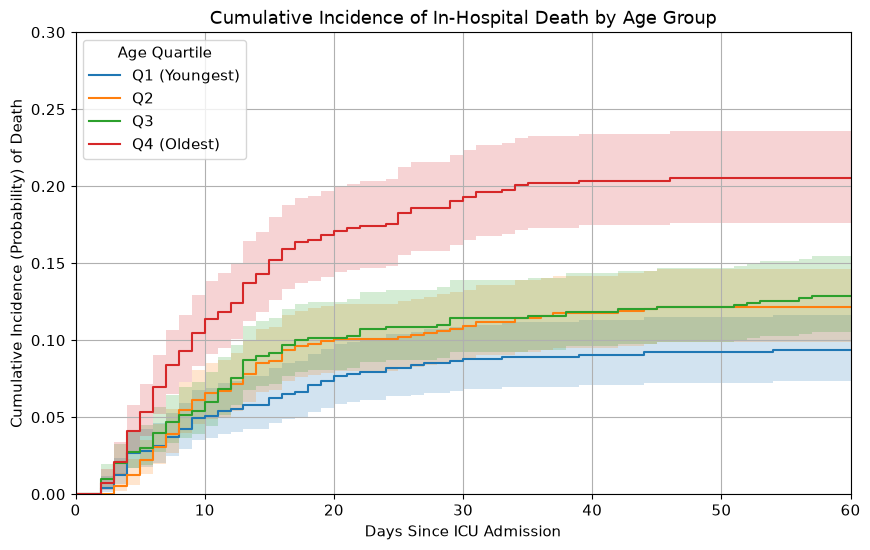

In [6]:
# --- 1. Prepare Data for the Plot ---
# We use data from the training set only for this check.
# Event coding: 1 = death (event of interest), 2 = discharge (competing event)
event_type_train = np.where(train_df["event_death"] == 1, 1, 2)
time_train = train_df["duration_days"]
age_series = train_df["Age"]

# Create Age Bands (quartiles) for plotting
# The try/except block makes our code robust if quartiles can't be calculated
try:
    age_band = pd.qcut(age_series, q=4, labels=["Q1 (Youngest)", "Q2", "Q3", "Q4 (Oldest)"])
except Exception:
    edges = [age_series.min(), 50, 70, 85, age_series.max()]
    age_band = pd.cut(age_series, bins=edges, include_lowest=True)

# --- 2. Calculate and Plot the Cumulative Incidence ---
fig, ax = plt.subplots(figsize=(10, 6))

for label in age_band.cat.categories:
    idx = (age_band == label)
    
    # Estimate CIF with pointwise confidence intervals
    time_points, cif, conf_int = cumulative_incidence_competing_risks(
        event=event_type_train[idx],
        time_exit=time_train[idx],
        conf_type="log-log"
    )
    
    # scikit-survival returns cif[0] = all causes combined, cif[1] = event 1 (death), cif[2] = event 2 (discharge)
    ax.step(time_points, cif[1], where="post", label=label)
    ax.fill_between(time_points, conf_int[1, 0], conf_int[1, 1], step="post", alpha=0.2)

ax.set_title("Cumulative Incidence of In-Hospital Death by Age Group")
ax.set_xlabel("Days Since ICU Admission")
ax.set_ylabel("Cumulative Incidence (Probability) of Death")
ax.set_xlim(0, 60)
ax.set_ylim(0, 0.3)
ax.legend(title="Age Quartile")
ax.grid(True)
plt.show()

### Clinical conclusions from the CIF plot

* The oldest quartile (red) has a clearly higher absolute risk: about **20%** in-hospital death by day 30 to 60, versus about **9%** in the youngest quartile. The middle quartiles sit around 12%
* The curves separate within the first 10 days and the gap holds. The oldest group's confidence band does not overlap with the youngest
* **Stakeholder translation:** "roughly 1 in 5 of our oldest ICU patients die in hospital, compared with about 1 in 11 of the youngest"
* **Watch out:** this is still one variable at a time. Older patients may also be sicker or sit in different ICUs. The multivariable model separates these effects

# 5. Multivariable Cox Proportional Hazards Model

Our previous analyses proved that looking at one variable at a time is misleading due to confounding. The solution is to build a **multivariable model**, which estimates the effect of each predictor while simultaneously controlling for the effects of all others.

We will use the preprocessing pipeline we defined in the previous step to ensure our data is clean and consistently formatted.

**What we do next**
* Combine our preprocessed features (`X_train_tr`) with the outcome data (`y_train`).
* Fit the `CoxPHFitter` model on this complete, preprocessed training dataset.
* Evaluate the model's performance by checking its concordance on both the training and validation sets.

In [7]:
# 5. Multivariable Cox proportional hazards model

# Safety checks
for name in ["X_train", "X_val", "y_train", "y_val"]:
    if name not in globals():
        raise NameError(f"{name} not defined. Ensure section 3.2 ran successfully")

# 1) Detect feature types and build preprocessor with utils
numeric_cols, categorical_cols = utils.detect_feature_types(X_train)
cox_preprocessor = utils.build_preprocessor(
    numeric_cols=numeric_cols,
    categorical_cols=categorical_cols,
    num_strategy="median",
    cat_strategy="most_frequent"
)

# 2) Fit on TRAIN ONLY and transform splits
cox_preprocessor.fit(X_train)
X_train_cox = utils.to_dataframe(cox_preprocessor, X_train)
X_val_cox   = utils.to_dataframe(cox_preprocessor, X_val)

# 3) Build modeling frames for lifelines
train_cox_df = pd.concat([X_train_cox, y_train[["duration_days", "event_death"]]], axis=1)
val_cox_df   = pd.concat([X_val_cox,   y_val[["duration_days", "event_death"]]],   axis=1)

# 4) Fit Cox PH with Efron ties and a small L2 penalizer for stability
cph_multi = CoxPHFitter(penalizer=0.01)
cph_multi.fit(train_cox_df, duration_col="duration_days", event_col="event_death")

print("--- Multivariable Cox model summary ---")
cph_multi.print_summary(
    decimals=3,
    columns=["coef", "exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]
)

# 5) Concordance baseline
cindex_train = float(cph_multi.concordance_index_)
cindex_val = float(cph_multi.score(val_cox_df, scoring_method="concordance_index"))
print(f"\nConcordance | train {cindex_train:.3f} | validation {cindex_val:.3f}")

# Keep objects for next steps
cox_feature_names = X_train_cox.columns.tolist()


--- Multivariable Cox model summary ---


<lifelines.CoxPHFitter: fitted with 2800 total observations, 2412 right-censored observations>
             duration col = 'duration_days'
                event col = 'event_death'
                penalizer = 0.01
                 l1 ratio = 0.0
      baseline estimation = breslow
   number of observations = 2800
number of events observed = 388
   partial log-likelihood = -2613.857
         time fit was run = 2026-10-22 11:57:12 UTC

---
              coef exp(coef) exp(coef) lower 95% exp(coef) upper 95%       p
covariate                                                                   
num__Age     0.020     1.020               1.013               1.026 <0.0005
num__Gender -0.017     0.983               0.804               1.202   0.870
num__SAPS-I  0.003     1.003               0.981               1.024   0.813
num__SOFA    0.069     1.072               1.042               1.103 <0.0005
num__Weight -0.004     0.996               0.992               1.001   0.095
num__CCU    -0.230     0.795               0.594               1.063   0.122
num__CSRU   -1.374     0.253               0.182               0.353 <0.0005
num__SICU   -0.427     0.653               0.519               0.820 <0.0005
---
Concordance = 0.697
Partial AIC = 5243.714
log-likelihood ratio test = 143.872 on 8 df
-log2(p) of ll-ratio test = 87.800


Concordance | train 0.697 | validation 0.698


### Multivariable Cox model: interpretation

This model estimates the effect of each admission factor **while holding the others constant**

---
#### What the model says

* **Overall discrimination is moderate:** C-index ≈ **0.70** on both train and validation (no sign of overfitting)
* **SOFA is a strong driver:** HR ≈ **1.07 per point** (p < 0.001). A 5-point higher SOFA means about **42% higher** daily risk of in-hospital death (1.072^5 ≈ 1.42)
* **Age stays important after adjustment:** HR ≈ **1.02 per year**, about 22% higher risk per 10 years (p < 0.001). The age effect is not just "older patients are sicker"
* **ICU type matters a lot.** Reference group = **Medical ICU (MICU)**, the unit coded with CCU = CSRU = SICU = 0
    * Cardiac Surgery Recovery Unit (CSRU): HR ≈ **0.25**, about 75% lower risk than MICU
    * Surgical ICU (SICU): HR ≈ **0.65**, about 35% lower risk
    * Coronary Care Unit (CCU): HR ≈ 0.80, not significant
* **SAPS-I adds almost nothing** (HR ≈ 1.00, p = 0.81) once SOFA and age are in the model: the scores overlap (SAPS-I itself gives points for age and physiology)
* **Gender and weight** are not significant

---
#### Clinical takeaways

* **Use SOFA and age together for risk stratification.** They carry independent information
* **Always compare outcomes within or adjusted for ICU type.** A raw mortality comparison between CSRU and MICU would mostly reflect case mix (planned cardiac surgery vs medical emergencies), not quality of care
* **Do not stack overlapping scores** (SAPS-I + SOFA) and read each coefficient as "the effect" of that score: overlap makes individual coefficients unstable
* These are **associations**, not causes: lowering SOFA by treatment is not guaranteed to lower risk by 7% per point

## 5.1. Proportional Hazards Assumption Check

The model's main assumption is that the effect of each variable (its Hazard Ratio) is **constant over time**. e.g. it assumes the risk from a high `SOFA` score is the same on Day 2 as it is on Day 20. We test to ensure our conclusions are reliable.

We use a built-in `lifelines` function that performs a statistical test for each variable and plots the "Schoenfeld residuals" for any that might violate the assumption.

**What we are looking for**
* **Statistical Test**: A p-value greater than 0.05 for a variable suggests it meets the assumption
* **Residual Plot**: The plot should look like random noise with no obvious trend. A clear slope or pattern in the plot is a red flag that the variable's effect changes over time


   Bootstrapping lowess lines. May take a moment...

The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.





1. Variable 'num__Age' failed the non-proportional test: p-value is 0.0450.

   Advice 1: the functional form of the variable 'num__Age' might be incorrect. That is, there may
be non-linear terms missing. The proportional hazard test used is very sensitive to incorrect
functional forms. See documentation in link [D] below on how to specify a functional form.

   Advice 2: try binning the variable 'num__Age' using pd.cut, and then specify it in
`strata=['num__Age', ...]` in the call in `.fit`. See documentation in link [B] below.

   Advice 3: try adding an interaction term with your time variable. See documentation in link [C]
below.


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


2. Variable 'num__SOFA' failed the non-proportional test: p-value is 0.0023.

   Advice 1: the functional form of the variable 'num__SOFA' might be incorrect. That is, there may
be non-linear 

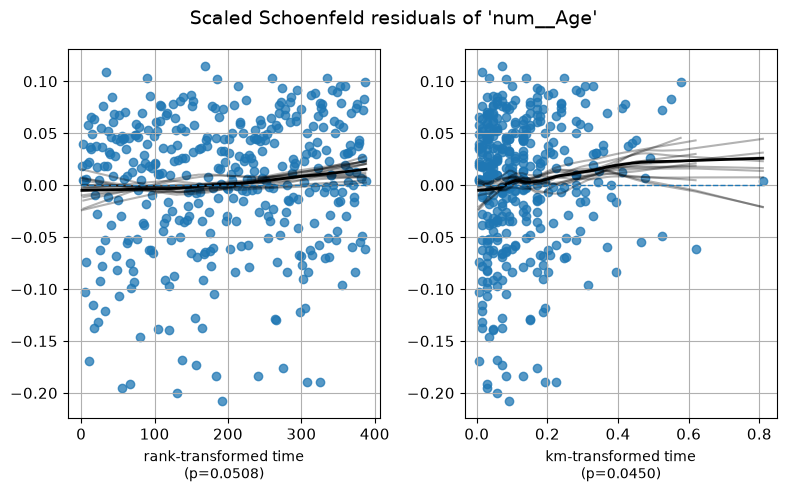

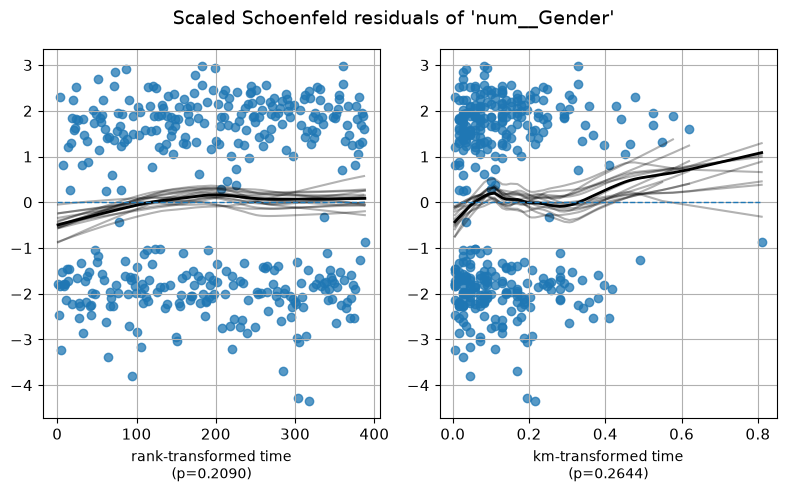

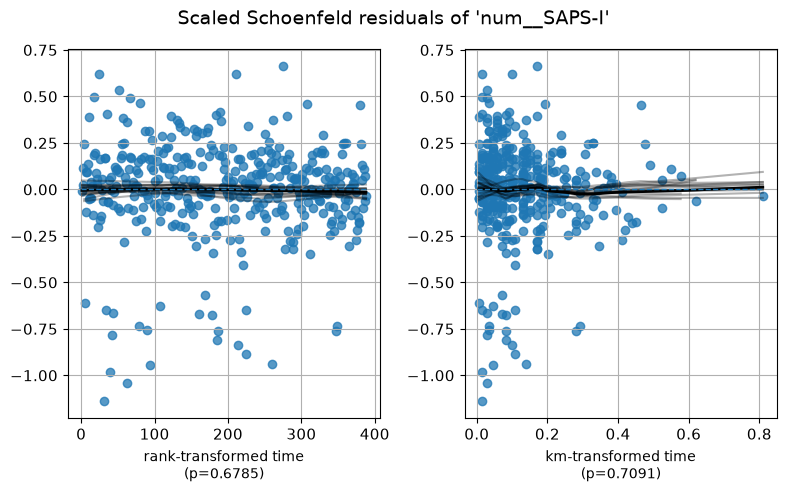

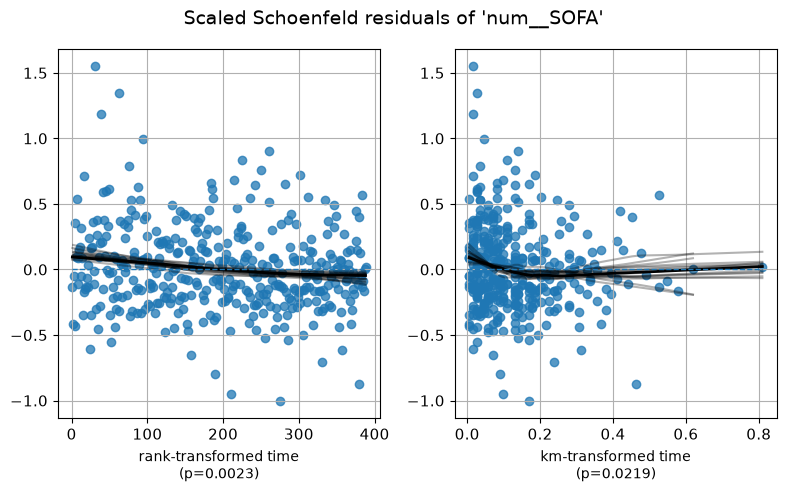

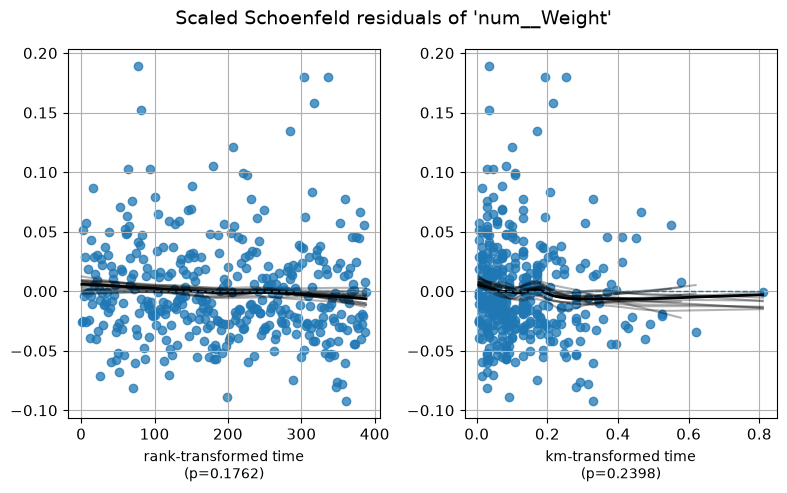

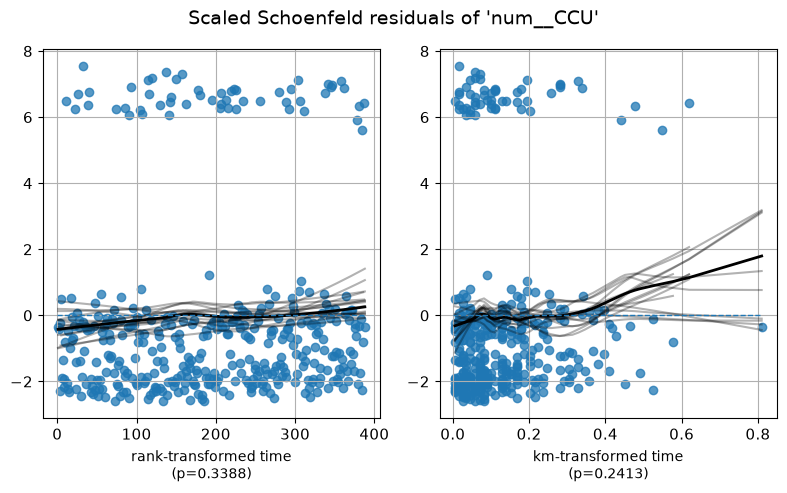

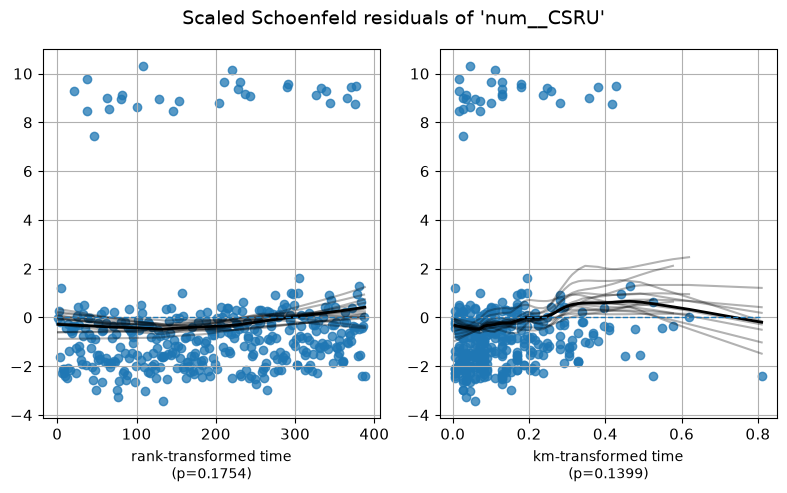

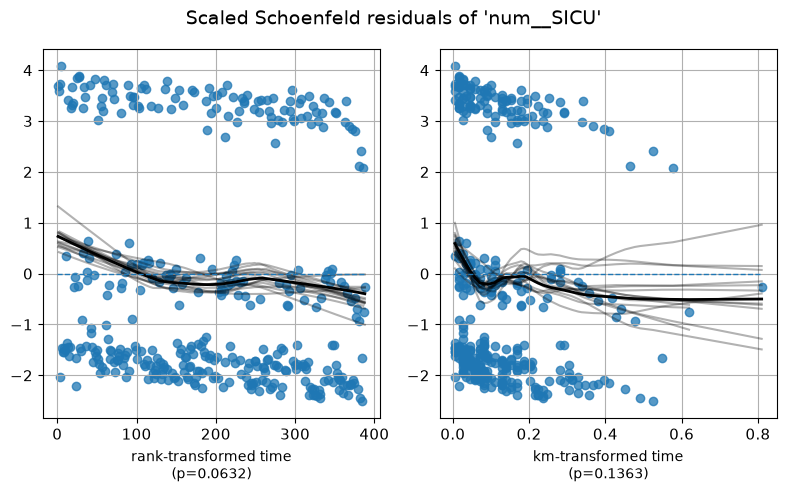

In [8]:
# --- 1. Run the Proportional Hazards Assumption Check ---
# We use the fitted multivariable model (cph_multi) and the processed training data
# The function will automatically flag any variables that fail the test (p < 0.05)

cph_multi.check_assumptions(
    training_df=train_cox_df,
    p_value_threshold=0.05,
    show_plots=True
)

# 2) Convenience: print the covariate names that might be most at risk of non-PH
suspect_terms = [c for c in train_cox_df.columns if any(k in c.lower() for k in ["sofa", "ccu", "csru", "sicu", "age"])]
print("\nCovariates to scrutinize first:", suspect_terms)


### Reading the result and what to do when the assumption fails

**In our model:** `SOFA` (p ≈ 0.002) and `Age` (p ≈ 0.045) fail the proportional hazards (PH) test. This matches the log-minus-log plot in notebook 01: the effect of admission severity is strongest in the first days and fades later. The HR of 1.07 for SOFA is an average over the whole stay; early on the true effect is larger, later it is smaller

A failed test does not make the model useless, but the HR for those variables needs care. Remedies:

1. **Stratification:** stratify by a binned version of the variable (e.g. `strata=["SOFA_band"]`). Each band gets its own baseline hazard. Downside: you lose the HR for that variable
2. **Time-varying effect:** add an interaction with time (e.g. `SOFA × log(time)`) to estimate how the effect changes
3. **Fixed horizons:** report risk at 7 and 30 days (sections 6.3 to 6.5, and notebook 03), which does not depend on a single constant HR

**Stakeholder translation:** "Admission SOFA tells us a lot about the first week and less about week three. Re-assess patients with fresh scores instead of relying on the admission value for the whole stay"

## 5.2 Forest Plot: Visualizing the Model's Results

The summary table gives us the precise numbers, but a **forest plot** helps us see the results at a glance. It's a standard way to visualize the output of a regression model.

How to Read the Forest Plot
- Each variable from our model is on the y-axis
- The x-axis shows the **Hazard Ratio (HR)**
- The dot represents the HR for that variable
- The horizontal line through the dot is the **95% confidence interval**
- The vertical dashed line is at HR = 1.0 (no effect)
- If a variable's confidence interval (the horizontal line) does **not** cross the vertical "no effect" line, it is statistically significant

--- Forest Plot of Multivariable Cox Model ---


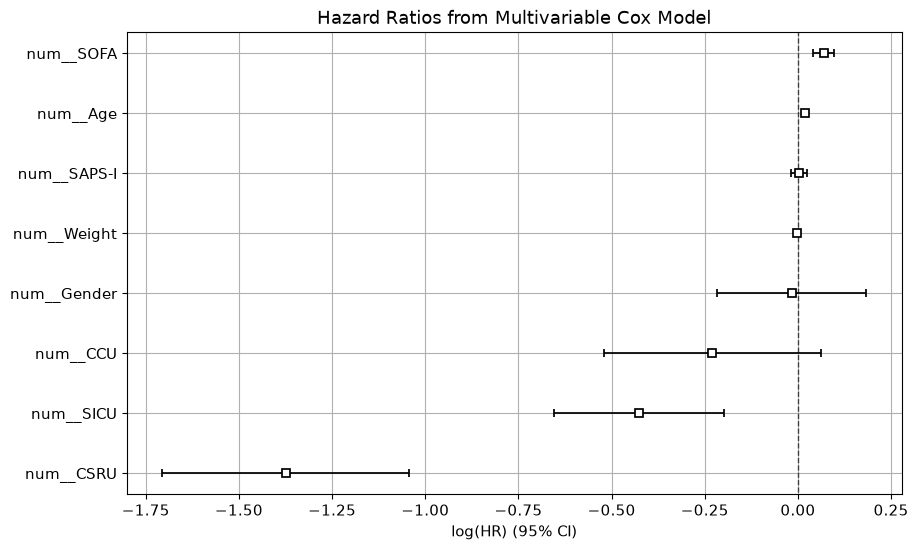

In [9]:
# The lifelines library has a convenient built-in function to create a forest plot.
# This is much simpler than building it manually.

print("--- Forest Plot of Multivariable Cox Model ---")
fig, ax = plt.subplots(figsize=(10, 6))

cph_multi.plot(ax=ax)

ax.set_title("Hazard Ratios from Multivariable Cox Model")
plt.show()

**Clinical insight from the forest plot**

- **SOFA** and **Age**: small boxes just right of 0 on the log scale, with confidence intervals (CIs) entirely above 0 → per-unit effects are small but precise and they add up (5 SOFA points ≈ HR 1.4; 10 years ≈ HR 1.2)
- **CSRU** and **SICU**: CIs entirely left of 0 → clearly lower risk than the reference Medical ICU (HR ≈ 0.25 and 0.65)
- **CCU, Gender, Weight, SAPS-I**: CIs cross 0 → no clear independent effect in this model
- The x-axis shows log(HR) and 95% CI. log(HR) = 0 means HR = 1, no effect. Convert with HR = exp(coef)
- Note: per-unit HRs are not comparable across variables with different units (one SOFA point vs one year vs one kg). For a fair "importance" comparison, standardize the variables first or compare clinically meaningful steps
- Use these effects to explain and to guide triage, not to state absolute risk

# 6. Individualized Prediction and Risk Separation

Now let's shift our focus from population-level explanations to **individualized prediction**. We'll use our model to assign a risk score (hazard) to each patient and see how well it separates them into different risk groups (cohorts)

1. **Calculate a risk score** for each patient in the test set using the Cox model
2. **Divide patients into four risk groups** (quartiles) based on the distribution of risk in the **training set** (to prevent data leakage)
3. **Visualize the separation** of these groups on the test set using KM curves and quantify it with a log-rank test
4. **Calculate the C-index** on the test set to measure the model's discriminative power

#### Clinical considerations
- A good model should show **clear separation** between the KM curves for the different risk quartiles
- The **Concordance Index (C-index)** is a metric that quantifies such discrimination i.e. the probability that, for a random pair of patients, the patient who experiences the event first had a higher risk score predicted by the model. A C-index of **0.5 is random chance**, vs. **1.0 as a perfect prediction**

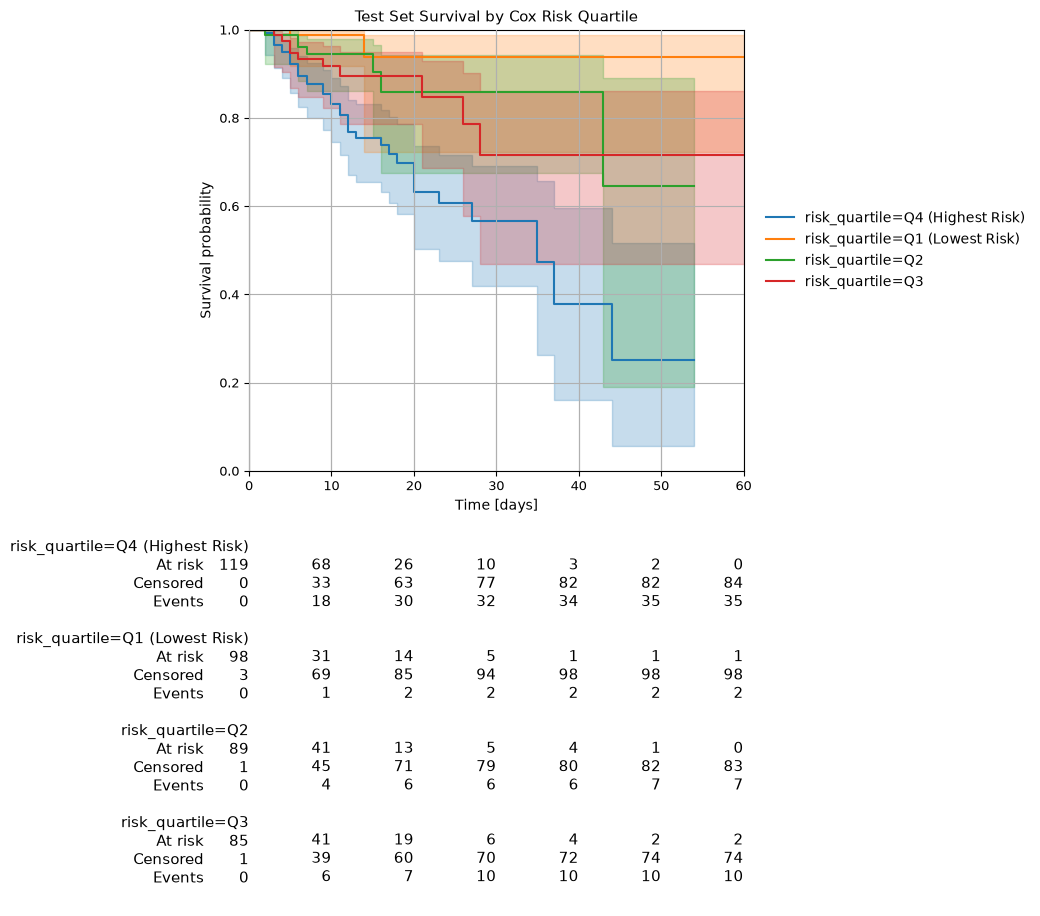

In [10]:
# Data preparation steps 1-3 remain the same
# 1) Transform features
X_test_cox = utils.to_dataframe(cox_preprocessor, X_test)
X_train_cox = utils.to_dataframe(cox_preprocessor, X_train)

# 2) Compute risk scores and define quartiles on the training set
risk_train = cph_multi.predict_partial_hazard(X_train_cox).values
risk_test = cph_multi.predict_partial_hazard(X_test_cox).values

q1, q2, q3 = np.quantile(risk_train, [0.25, 0.50, 0.75])
bins = [-np.inf, q1, q2, q3, np.inf]
labels = ["Q1 (Lowest Risk)", "Q2", "Q3", "Q4 (Highest Risk)"]
test_groups = pd.cut(risk_test, bins=bins, labels=labels, include_lowest=True)

# 3) Prepare evaluation DataFrame for the test set
test_eval_df = pd.concat(
    [y_test[["duration_days", "event_death"]].copy(),
     pd.Series(test_groups, index=X_test_cox.index, name="risk_quartile")],
    axis=1
).rename(columns={"duration_days": "duration", "event_death": "event"})

# 4) Plot with a larger figure size
fig, ax, logrank = utils.km_by_group(
    df=test_eval_df,
    group_col="risk_quartile",
    time_col="duration",
    event_col="event",
    xmax=60,
    show_table=True,
    figsize=(10, 6)
)

ax.set_title("Test Set Survival by Cox Risk Quartile", fontsize=11)
ax.set_xlabel(ax.get_xlabel(), fontsize=10)
ax.set_ylabel(ax.get_ylabel(), fontsize=10)
ax.tick_params(axis='both', which='major', labelsize=9)

for item in ax.texts:
    item.set_fontsize(9)

ax.legend(
    loc='center left',
    bbox_to_anchor=(1.02, 0.5),
    frameon=False,
    fontsize=10
)

fig.subplots_adjust(right=0.75, bottom=0.2)
plt.show()

**Clinical insights**
- **The ranking works:** the highest-risk quartile (Q4) drops fastest and the lowest (Q1) stays near the top, with very few deaths. The middle quartiles overlap, which is typical with a C-index around 0.70
- **Discrimination is not calibration:** this plot shows the model ranks patients well. It does not prove the predicted probabilities are right. Calibration is checked in 6.5 and 6.6
- **Association is not causation:** risk groups are built on associations. Do not use them alone to choose treatments
- **Small numbers:** the test set has about 400 patients and few deaths per quartile, hence the wide bands. Focus on the first 2 to 3 weeks where most patients are still observed
- **So what:** a simple use case is a daily "top-quartile list" for the senior round. Before that, check how many patients per day this flags and whether the team can act on it

## 6.2 Personalized Survival Predictions

The risk quartiles showed that the model does a moderate job separating group of patients. Now, let's visualize the full survival curve for specific individuals. This transforms the model's **abstract risk score into a tangible, time-dependent forecast for a given patient**

We will select two patients from the **test set**:
1. One with the lowest predicted risk
2. One with the highest

Plotting their predicted survival functions, will illustrate the practical implications of the model's predictions.

**Pitfalls & Considerations**
- Do not report beyond the study follow-up window since extrapolation is unreliable  
- Predictions rely on the proportional hazards assumption and the estimated baseline  
- Associations in Cox are not causal, avoid treatment recommendations based solely on these numbers  

Feature values for the selected low-risk and high-risk patients:


,num__Age,num__Gender,num__SAPS-I,num__SOFA,num__Weight,num__CCU,num__CSRU,num__SICU
3795,38.0,0.0,2.0,1.0,86.3,0.0,1.0,0.0
1143,90.0,1.0,30.0,15.0,71.6,0.0,0.0,0.0


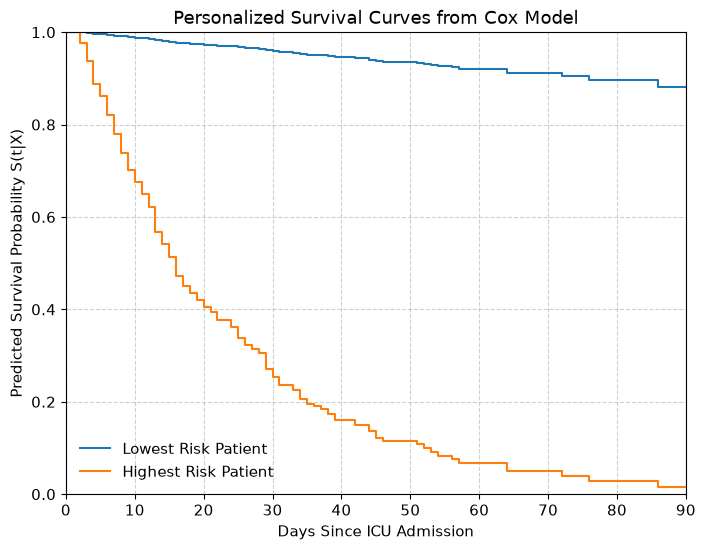


--- Fixed-Horizon Predictions ---



,Low-Risk Survival,Low-Risk Mortality,High-Risk Survival,High-Risk Mortality
7-Day,99.24%,0.76%,78.01%,21.99%
30-Day,95.88%,4.12%,25.43%,74.57%
60-Day,92.03%,7.97%,6.70%,93.30%


In [11]:
# Requires: X_test_cox, risk_test, cph_multi from the previous cell
# Produces: A plot of survival curves for two example patients and their fixed-horizon survival probabilities

# 1. Find the index for the lowest and highest-risk patients in the TEST set
low_risk_idx  = X_test_cox.index[np.argmin(risk_test)]
high_risk_idx = X_test_cox.index[np.argmax(risk_test)]
patient_pair_df = X_test_cox.loc[[low_risk_idx, high_risk_idx]]

print("Feature values for the selected low-risk and high-risk patients:")
display(patient_pair_df)

# 2. Predict the full survival functions for these two patients
# The result is a DataFrame with time-points as the index and patients as columns
survival_functions = cph_multi.predict_survival_function(patient_pair_df)

# 3. Plot the personalized survival curves
plt.figure(figsize=(8, 6))
plt.step(survival_functions.index, survival_functions.iloc[:, 0], where="post", label="Lowest Risk Patient")
plt.step(survival_functions.index, survival_functions.iloc[:, 1], where="post", label="Highest Risk Patient")

plt.xlim(0, 90)
plt.ylim(0, 1)
plt.xlabel("Days Since ICU Admission")
plt.ylabel("Predicted Survival Probability S(t|X)")
plt.title("Personalized Survival Curves from Cox Model")
plt.legend(frameon=False)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# 4. Extract survival probabilities and display them in a formatted table
eval_times = [7.0, 30.0, 60.0]
sf_at_times = cph_multi.predict_survival_function(patient_pair_df, times=eval_times)

# Create a clean DataFrame for the results
results_df = pd.DataFrame({
    'Low-Risk Patient': sf_at_times.iloc[:, 0].values,
    'High-Risk Patient': sf_at_times.iloc[:, 1].values
}, index=[f"{int(t)}-Day" for t in eval_times])

# Add mortality risk columns
results_df['Low-Risk Mortality'] = 1 - results_df['Low-Risk Patient']
results_df['High-Risk Mortality'] = 1 - results_df['High-Risk Patient']

# Rename survival columns for clarity
results_df.rename(columns={'Low-Risk Patient': 'Low-Risk Survival', 'High-Risk Patient': 'High-Risk Survival'}, inplace=True)

print("\n--- Fixed-Horizon Predictions ---\n")
# Display the styled DataFrame
display(results_df[['Low-Risk Survival', 'Low-Risk Mortality', 'High-Risk Survival', 'High-Risk Mortality']].style.format("{:.2%}").set_caption("Predicted Survival & Mortality Risk"))

#### Interpreting individual predictions

**The lowest-risk patient** (38 years, SOFA 1, CSRU)
- Flat, high curve: about 0.8% predicted risk at 7 days and 4% at 30 days
- **Implication:** standard pathway, early step-down planning once clinical criteria are met

**The highest-risk patient** (90 years, SOFA 15, SAPS-I 30, Medical ICU)
- Steep early decline: about 22% at 7 days and 75% at 30 days
- **Implication:** intensified monitoring in the first week and an early goals-of-care conversation with the family

**Watch out: these numbers are too high for absolute risk.** They come from 1 − S(t) of a model that treats discharge as censoring, i.e. "risk if the patient could never be discharged". For an absolute probability we need the competing-risks version in section 6.5. Use these curves to **compare** patients, not to quote a percentage to a family

**Other limitations**
- **Association, not causation:** do not make treatment decisions from the model output alone
- **Assumptions matter:** SOFA and age violate PH (section 5.1), so the curve shape is an approximation
- **Avoid extrapolation:** beyond about 60 days very few patients remain, so tail predictions are unreliable

## 6.3 Time-Dependent Model Performance

The **Concordance (C-index)** gives us a single number for model performance over the entire follow-up period e.g. 90 days. However, in a clinical setting, performance at specific time points is often more important:

_**"How well does our model predict the risk of in-hospital death at 7 days, 30 days, and 60 days, for the set of patients still in the ICU at those times?"**_

Remember, in our case, we're not predicting the *absolute* 7-day mortality for a new patient. Instead, we are evaluating the *cause-specific hazard* performance at different points in time

Key metrics:

1.  **Time-Dependent AUC**: This measures the model's **discrimination** at a specific time *t*. It quantifies how well the model's risk score distinguishes between patients who die in hospital before time *t* and those still in hospital beyond time *t*

2.  **Brier Score**: This measures the model's overall prediction accuracy for the **cause-specific hazard**. It calculates the error between the predicted survival probabilities and the actual outcomes (in-hospital death or discharge treated as censoring) at time *t*

In [12]:
# --- 1. Setup ---
eval_times = np.array([7.0, 30.0, 60.0], dtype=float)
y_train_surv = Surv.from_arrays(
    event=y_train["event_death"].astype(bool).to_numpy(),
    time=y_train["duration_days"].to_numpy(dtype=float)
)
y_test_surv = Surv.from_arrays(
    event=y_test["event_death"].astype(bool).to_numpy(),
    time=y_test["duration_days"].to_numpy(dtype=float)
)


# --- 2. Time-Dependent AUC (Corrected Logic) ---
def get_auc_at_time(t):
    """
    Robustly calculates AUC at a single time t, handling data insufficiency
    and varied output formats from the scikit-survival library.
    """
    # Check for sufficient data in both train and test sets
    events_train = y_train["event_death"].astype(bool)
    times_train = y_train["duration_days"]
    train_ok = (events_train & (times_train <= t)).any() and (times_train > t).any()
    
    events_test = y_test["event_death"].astype(bool)
    times_test = y_test["duration_days"]
    test_ok = (events_test & (times_test <= t)).any() and (times_test > t).any()
    
    if not (train_ok and test_ok):
        return np.nan
    
    # Calculate AUC
    raw_output = cumulative_dynamic_auc(y_train_surv, y_test_surv, risk_test, [t])
    
    # Handle inconsistent return formats from the library
    # Sometimes it returns a tuple (times, scores), sometimes just scores
    if isinstance(raw_output, tuple):
        auc_scores_array = raw_output[1]
    else:
        auc_scores_array = raw_output
        
    # Ensure the result is a 1D array and return the first (and only) score
    return np.atleast_1d(auc_scores_array)[0]

# Calculate AUC for each time point
auc_scores = [get_auc_at_time(t) for t in eval_times]


# --- 3. Brier Score Calculation ---
sf_at_times = cph_multi.predict_survival_function(X_test_cox, times=eval_times)
survival_prob_matrix = sf_at_times.T.to_numpy()
_, brier_scores = brier_score(y_train_surv, y_test_surv, survival_prob_matrix, eval_times)


# --- 4. Assemble and Display Results ---
performance_df = pd.DataFrame({
    "Time Horizon (Days)": eval_times.astype(int),
    "Time-Dependent AUC": auc_scores,
    "Brier Score": brier_scores
})

print("\n--- Time-Dependent Model Performance ---\n")
display(performance_df.style.format({
    "Time-Dependent AUC": "{:.3f}",
    "Brier Score": "{:.3f}"
}).hide(axis="index"))


--- Time-Dependent Model Performance ---



Time Horizon (Days),Time-Dependent AUC,Brier Score
7,0.680,0.067
30,0.723,0.172
60,0.783,0.162


#### Clinical insights and interpretation

**How to read these numbers**
- **Time-dependent AUC** rises from about **0.68 at 7 days** to **0.72 at 30 days** and **0.78 at 60 days**. The admission variables rank patients moderately well for the short term and better for "will this patient ever die in hospital"
- **Brier score** (mean squared error of the predicted probability, lower is better): 0.07 at 7 days, about 0.17 at 30 and 60 days. Numbers grow with the horizon because more deaths have happened by then, so there is more to get wrong. A Brier score means little alone; section 6.4 compares it to a baseline

**Limitations**
- These metrics treat discharge as non-informative censoring. They evaluate the cause-specific model ("risk while in hospital"), not the absolute probability of death with discharge competing
- **So what:** with only admission data, the model is better at long-horizon ranking than at spotting who will die this week. Short-term alerts need data that update during the stay (notebook 03 uses first-48-hour measurements)

## 6.4 Comparing the Model to a Simple Baseline

But are these numbers good? To find out, we need to compare them to a reference point.

We'll create a simple **baseline model** that ignores all patient-specific features. It predicts the same survival probability for every patient, based on the overall survival rate of the training cohort (calculated with a Kaplan-Meier estimator).

By comparing our Cox model to this naive baseline, we can calculate the **Brier Skill Score (BSS)**. This tells us how much better our model is than simply guessing the population average. A positive BSS means our model has learned useful patterns from the patient data.

In [13]:
# 1. Fit a Kaplan-Meier estimator on the TRAINING data to create the baseline
kmf_baseline = KaplanMeierFitter()
kmf_baseline.fit(y_train["duration_days"], y_train["event_death"])

# 2. Get the baseline survival probability predictions at our evaluation times
# This gives one probability for each time point, which we apply to all test patients
baseline_surv_probs = np.asarray(kmf_baseline.predict(eval_times).values)

# 3. Create the prediction matrix required by brier_score
# We repeat the baseline predictions for every patient in the test set
n_test_patients = len(y_test_surv)
baseline_pred_matrix = np.tile(baseline_surv_probs, (n_test_patients, 1))

# 4. Calculate the Brier score for this baseline model
_ , baseline_brier_scores = brier_score(
    y_train_surv, y_test_surv, baseline_pred_matrix, eval_times
)

# 5. Calculate the Brier Skill Score (BSS)
# 'brier_scores' is the brier score from our Cox model in the previous cell
brier_skill_scores = 1 - (brier_scores / baseline_brier_scores)

# 6. Display the results in a comparative table
results_df = pd.DataFrame({
    'Cox Model Brier Score': brier_scores,
    'Baseline Brier Score': baseline_brier_scores,
    'Brier Skill Score (BSS)': brier_skill_scores
}, index=[f"{int(t)}-Day" for t in eval_times])

print("\n--- Brier Score Comparison ---\n")
display(results_df.style.format("{:.3f}"))


--- Brier Score Comparison ---



,Cox Model Brier Score,Baseline Brier Score,Brier Skill Score (BSS)
7-Day,0.067,0.068,0.027
30-Day,0.172,0.206,0.163
60-Day,0.162,0.212,0.234


#### Clinical insights

- The Brier Skill Score (BSS) is positive at all horizons, so the Cox model beats "give everyone the average risk"
- But the gain is **tiny at 7 days (BSS ≈ 0.03, i.e. 3% better)** and grows at 30 days (≈ 0.16) and 60 days (≈ 0.23)
- **So what:** for early (first-week) decisions, these admission variables add little over the average risk. For longer-horizon planning (e.g. who will need a long-stay pathway or an early palliative-care discussion) the model adds real value
- **Stakeholder translation:** "Admission data alone will not tell us who is in danger this week. They do help identify, on day 1, the group with the highest chance of dying during the stay"

## 6.5 Estimating True Absolute Risk with a Competing Risks Model

We now address the competing risk of discharge directly. Our goal now, is to answer a most clinically relevant question:

_**"What is the actual probability that a patient will die in the hospital by "day 7", considering they could be discharged first?"**_

**The Cause-Specific Hazards Method**
To solve this, we will build two separate Cox models, as a standard/ robust approach:

1.  **The Death Model**: Predicts the hazard of *death* (treating discharge as censoring).
2.  **The Discharge Model**: Predicts the hazard of *discharge* (treating death as censoring).

We will then combine the hazards from both models to calculate the **Cumulative Incidence Function (CIF)**. The CIF gives us the true, absolute probability of death over time.

3. Finally, we will check how well our model is **calibrated** by comparing its average predicted risk to the actual observed risk in the test set

In [14]:
# 6.5 Competing risks with cause-specific Cox focused on 7 days

# 0) Ensure we have an explicit discharge indicator
for df_name in ["y_train", "y_val", "y_test"]:
    if df_name in globals():
        df = globals()[df_name]
        if "event_discharge" not in df.columns:
            df["event_discharge"] = (df["event_death"] == 0).astype(int)

COMPETING_COL = "event_discharge"
H = np.array([7.0, 30.0, 60.0], dtype=float)  # we still compute all, but 7 d is the focus

# 1) Preprocess features
X_tr = utils.to_dataframe(cox_preprocessor, X_train)
X_te = utils.to_dataframe(cox_preprocessor, X_test)

# 2) Cause-specific training frames
def _cs(X_df, y_df, event_col):
    out = pd.concat(
        [X_df.reset_index(drop=True),
         y_df[["duration_days", "event_death", COMPETING_COL]].reset_index(drop=True)],
        axis=1
    )
    out["event_for_model"] = (out[event_col] == 1).astype(int)
    return out[["duration_days", "event_for_model"] + list(X_df.columns)]

df_tr_death = _cs(X_tr, y_train, "event_death")
df_tr_disc  = _cs(X_tr, y_train, COMPETING_COL)

# 3) Fit cause-specific Cox models
cph_death = CoxPHFitter().fit(df_tr_death, "duration_days", "event_for_model", show_progress=False)
cph_disc  = CoxPHFitter().fit(df_tr_disc,  "duration_days", "event_for_model", show_progress=False)

# 4) Predict patient-level CIF of death on the TEST set
pred_cif_df = utils.predict_cif_from_csh(cph_death, cph_disc, X_te, H)  # CIF_7d, CIF_30d, CIF_60d
display(pred_cif_df.round(3).head(10))

# 5) Calibration at 7 days using nonparametric CIF by quartile
calib_7d_df = utils.check_calibration_competing_risk_at(
    y_true=y_test,
    predictions=pred_cif_df["CIF_7d"],
    duration_col="duration_days",
    event_col="event_death",
    competing_col=COMPETING_COL,
    horizon_days=7.0,
    n_bins=4
).rename(columns={"pred_mean_risk": "pred_mean_risk_7d", "obs_risk": "obs_risk_7d"}).round(3)

display(calib_7d_df)


,CIF_7d,CIF_30d,CIF_60d
23,0.028,0.068,0.073
3888,0.025,0.080,0.100
3487,0.030,0.061,0.063
3673,0.015,0.040,0.046
1889,0.046,0.103,0.108
475,0.018,0.040,0.043
3670,0.011,0.022,0.023
755,0.038,0.119,0.145
12,0.047,0.092,0.094
304,0.098,0.225,0.239


,risk_quartile,n,pred_mean_risk_7d,obs_risk_7d
0,Q1 lowest,99,0.015,0.010
1,Q2,99,0.032,0.040
2,Q3,99,0.057,0.061
3,Q4 highest,99,0.111,0.131


### Interpreting the 7-day absolute risk

This analysis tells us how far we can trust the probabilities the model produces

#### What the tables show

* **First table:** each patient's probability of dying in hospital within 7 days, with discharge as a competing event. Compare these values (mostly 1 to 10%) with the inflated 1 − S(t) values in section 6.2
* **Second table (reality check):** patients grouped by predicted risk, average predicted risk vs observed risk (non-parametric CIF) in that group

#### Insights

* **The ranking holds:** observed risk increases from the lowest to the highest quartile (about 1% → 13%)
* **The probabilities are close to reality:** predicted 1.5%, 3.2%, 5.7%, 11.1% vs observed 1.0%, 4.0%, 6.1%, 13.1%. With about 100 patients and only a handful of deaths per quartile, these gaps are within noise

#### Clinical takeaway

* The competing-risks Cox model gives usable absolute risks at 7 days
* Even the highest quartile has only about 13% risk. A "top quartile" flag at 7 days would generate many alerts for each true death: decide the threshold with clinicians using net benefit (notebook 03 and the deck)

## 6.6 Improving our Predictions with Calibration

To recalibrate our model, and ensure further medical usefulness and reliability, we'll use **Isotonic Regression** (Think of it as a smart "corrector" that learns the systematic error in our model's predictions)

- Fit isotonic regression on training evaluable patients  
- Apply to test predictions  
- Show quartile calibration and a familiar sklearn calibration plot

,risk_quartile,n,pred_raw_7d,pred_cal_7d,observed_7d
0,Q1 lowest,99,0.015,0.012,0.010
1,Q2,99,0.032,0.020,0.040
2,Q3,99,0.057,0.065,0.061
3,Q4 highest,99,0.111,0.124,0.131


,model,brier_7d,n_test_evaluable
0,Cox_CIF raw 7d,0.055,396
1,Cox_CIF calibrated 7d,0.055,396


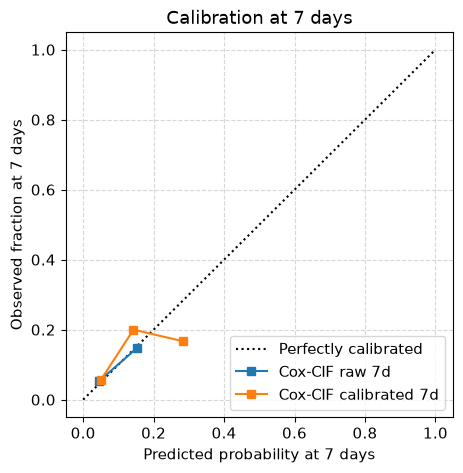

In [15]:
# 6.6 Isotonic calibration at 7 days
# 1) Raw 7 d probabilities from the same competing-risk models used above
p_train_raw_7 = utils.predict_cif_from_csh(cph_death, cph_disc, X_tr, np.array([7.0]))["CIF_7d"]
p_test_raw_7  = pred_cif_df["CIF_7d"]

# 2) Fixed-horizon labels and evaluable masks at 7 d
y_tr_7, eval_tr_7 = utils.get_fixed_horizon_labels(y_train, 7.0)
y_te_7, eval_te_7 = utils.get_fixed_horizon_labels(y_test, 7.0)

# 3) Fit isotonic on TRAIN evaluable and apply to TEST
iso_7 = IsotonicRegression(out_of_bounds="clip")
iso_7.fit(p_train_raw_7[eval_tr_7], y_tr_7[eval_tr_7])

p_test_cal_7 = pd.Series(iso_7.transform(p_test_raw_7), index=p_test_raw_7.index, name="p_cal_7d")

# 4) Calibration by quartile on TEST at 7 d: before vs after vs observed
cal_raw_7 = utils.check_calibration_competing_risk_at(
    y_true=y_test,
    predictions=p_test_raw_7,
    duration_col="duration_days",
    event_col="event_death",
    competing_col=COMPETING_COL,
    horizon_days=7.0
).rename(columns={"pred_mean_risk": "pred_raw_7d", "obs_risk": "observed_7d"})

cal_cal_7 = utils.check_calibration_competing_risk_at(
    y_true=y_test,
    predictions=p_test_cal_7,
    duration_col="duration_days",
    event_col="event_death",
    competing_col=COMPETING_COL,
    horizon_days=7.0
).rename(columns={"pred_mean_risk": "pred_cal_7d"})

calibr_table_7d = (
    cal_raw_7.merge(cal_cal_7[["risk_quartile", "pred_cal_7d"]], on="risk_quartile")
             .loc[:, ["risk_quartile", "n", "pred_raw_7d", "pred_cal_7d", "observed_7d"]]
             .round(3)
)
display(calibr_table_7d)

# 5) Brier score on TEST evaluable patients at 7 d: before vs after
brier_7d_df = pd.DataFrame({
    "model": ["Cox_CIF raw 7d", "Cox_CIF calibrated 7d"],
    "brier_7d": [
        brier_score_loss(y_te_7[eval_te_7], p_test_raw_7[eval_te_7]),
        brier_score_loss(y_te_7[eval_te_7], p_test_cal_7[eval_te_7])
    ],
    "n_test_evaluable": int(eval_te_7.sum())
}).round({"brier_7d": 3})
display(brier_7d_df)

# 6) Familiar sklearn visualization for evaluable TEST patients at 7 d
utils.plot_calibration_at_horizon(
    y_true_bin=y_te_7,
    y_prob_raw=p_test_raw_7.to_numpy(copy=False),
    y_prob_cal=p_test_cal_7.to_numpy(copy=False),
    mask=eval_te_7,
    horizon_days=7.0,
    n_bins=8
)


#### What the calibration results show

* A perfectly calibrated model falls on the **dotted diagonal**
* **Raw model (blue):** close to the diagonal in the range where most patients are (below 20% risk)
* **Isotonic-calibrated model (orange):** the Brier score does not improve (0.055 for both). The isotonic step mostly reshuffles the predictions in the top bins, where there are very few patients

**Lesson:** recalibration is a fix for a model that is **miscalibrated**. When the raw probabilities are already close to the diagonal, a flexible calibrator fitted on a few hundred patients adds noise rather than accuracy. Always compare before vs after on held-out data and keep the simpler option when they tie

**At 30 and 60 days (plots below):** both versions track the diagonal at low and medium risk. The points at the top right rest on very few patients, so do not over-read them

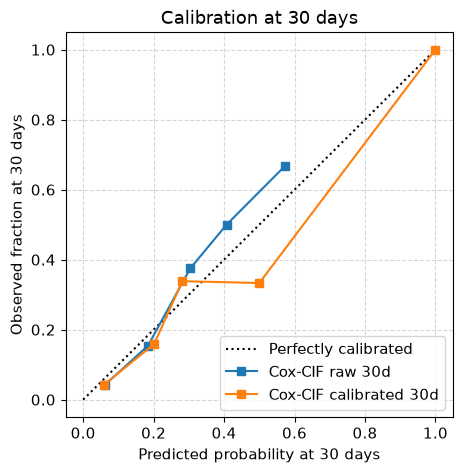

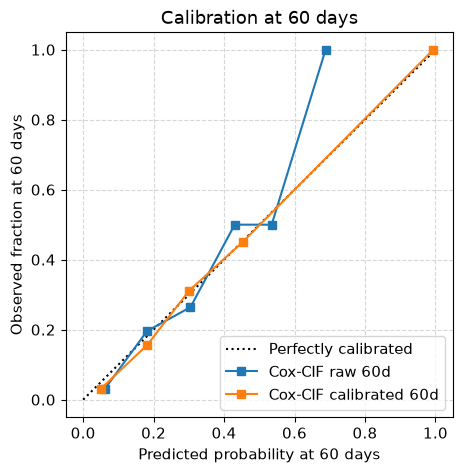

In [16]:
# Calibration plots at 30 and 60 days using the utils helper
# Horizons to visualize
H = [30.0, 60.0]

# Precompute design matrices if not already in memory
try:
    X_tr
    X_te
except NameError:
    X_tr = utils.to_dataframe(cox_preprocessor, X_train)
    X_te = utils.to_dataframe(cox_preprocessor, X_test)

for h in H:
    # 1) Raw probabilities from the competing-risk Cox models
    p_train_raw_h = utils.predict_cif_from_csh(cph_death, cph_disc, X_tr, np.array([h]))[f"CIF_{int(h)}d"]
    p_test_raw_h  = utils.predict_cif_from_csh(cph_death, cph_disc, X_te, np.array([h]))[f"CIF_{int(h)}d"]

    # 2) Fixed-horizon labels and evaluable mask
    y_tr_h, eval_tr_h = utils.get_fixed_horizon_labels(y_train, h)
    y_te_h, eval_te_h = utils.get_fixed_horizon_labels(y_test,  h)

    # 3) Horizon-specific isotonic calibration fitted on TRAIN evaluable patients
    iso_h = IsotonicRegression(out_of_bounds="clip")
    iso_h.fit(p_train_raw_h[eval_tr_h], y_tr_h[eval_tr_h])

    # 4) Plot sklearn-style calibration on TEST evaluable patients
    p_test_cal_h = iso_h.transform(p_test_raw_h)
    utils.plot_calibration_at_horizon(
        y_true_bin=y_te_h,
        y_prob_raw=p_test_raw_h.to_numpy(copy=False),
        y_prob_cal=p_test_cal_h,
        mask=eval_te_h,
        horizon_days=h,
        n_bins=8
    )



# 7. Key takeaways for stakeholders

| Question | Answer from this notebook |
|---|---|
| What drives in-hospital death risk, adjusted for the rest? | SOFA (+42% per 5 points), age (+22% per 10 years), ICU type (CSRU and SICU much lower than Medical ICU) |
| How well does the model rank patients? | Moderately: C-index ≈ 0.70, better at 30 to 60 days than at 7 days |
| Can we quote an absolute risk to a family? | Only from the competing-risks version (CIF), which is well calibrated at 7 days. Never from 1 − S(t) |
| Is a single hazard ratio enough? | Not for SOFA and age: their effect is stronger early in the stay |

**Recommended actions**
1. Adjust any mortality comparison between ICUs for case mix (at least SOFA, age, ICU type)
2. Use admission risk to plan the stay (long-stay pathway, early family meetings), not as a first-week alarm
3. For short-term alerts, add measurements from the first 48 hours (notebook 03)
4. Report absolute risk with the CIF and check calibration on held-out patients before any use
